# 1. Bounded scalar integrator

**Goal:** move a scalar state from 2.5 toward zero while limiting the input.
This is the smallest complete ICORE example.

$$\begin{aligned}
\min_{x_0,\ldots,x_N,u_0,\ldots,u_{N-1}}\quad
&\frac12\sum_{k=0}^{N-1}(x_k^2+0.2u_k^2)+\frac12\,8x_N^2\\
\text{subject to}\quad&x_0=2.5,\\
&x_{k+1}=x_k+0.25u_k,\qquad -1\le u_k\le1.
\end{aligned}$$


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

## 1. Dimensions and dynamics
There are N control inputs and N+1 states.

In [2]:
N, nx, nu = 20, 1, 1
dt = 0.25
A = np.ones((N, nx, nx))
B = dt * np.ones((N, nx, nu))
b = np.zeros((N, nx))
x0 = np.array([2.5])

## 2. Objective
The terminal state has a larger weight. Linear and cross terms are zero.

In [3]:
Q = np.ones((N + 1, nx, nx))
Q[-1] = 8.0
R = 0.2 * np.ones((N, nu, nu))
S = np.zeros((N, nu, nx))
q = np.zeros((N + 1, nx))
r = np.zeros((N, nu))
objective_offset = 0.0

## 3. Constraints
`G[k] @ [u[k], x[k]] <= h[k]`. The two rows are `+u <= 1` and `-u <= 1`.
At the terminal node there is no input; zero rows with positive bounds are harmless padding.

In [4]:
G = np.zeros((N + 1, 2, nu + nx))
h = np.ones((N + 1, 2))
G[:N, 0, 0] = 1.0
G[:N, 1, 0] = -1.0
F = np.empty((0, nx))
f = np.empty(0)

## 4. Give the arrays to ICORE and solve

`[u, x]` is the column order in each constraint row. The block cost is
$\tfrac12x^TQx + u^TSx + \tfrac12u^TRu + q^Tx + r^Tu$.
`F @ x[N] = f` is an optional terminal equality. An empty `F, f` means none.

The kernel and counters below come from the actual solve. A factorization policy
is **not** claimed to be a trace of every operation. Set `DETAILED=True` above
for an additional diagnostic replay; it is separate from solve timing.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE) as solver:
    solution = solver.solve()
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

# Solver returns your original coordinates, including when presolve was applied.
x = solution["x"]        # Shape (N + 1, nx).
u = solution["u"]        # Shape (N, nu); there is no terminal control.
print("Initial state:", x[0])
print("Final state:", x[-1])
print("First input:", u[0])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 6
Native solve (ms),0.158000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
5.107e-14,5.554e-15,1.596e-09,5.107e-14,0.000e+00,12.969678,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

Initial state: [2.5]
Final state: [0.00026368]
First input: [-1.]


## 5. Results

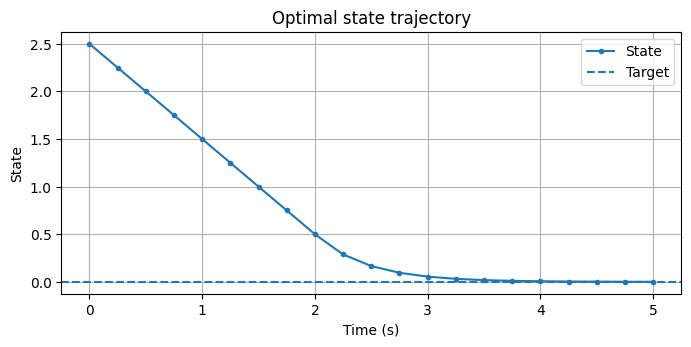

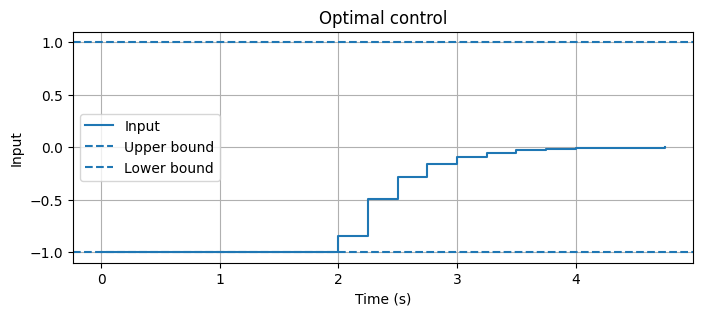

In [6]:
time_x = dt * np.arange(N + 1)
time_u = dt * np.arange(N)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(time_x, x[:, 0], marker=".", label="State")
ax.axhline(0.0, linestyle="--", label="Target")
ax.set(xlabel="Time (s)", ylabel="State", title="Optimal state trajectory")
ax.grid(True)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.step(time_u, u[:, 0], where="post", label="Input")
ax.axhline(1.0, linestyle="--", label="Upper bound")
ax.axhline(-1.0, linestyle="--", label="Lower bound")
ax.set(xlabel="Time (s)", ylabel="Input", title="Optimal control")
ax.grid(True)
ax.legend()
plt.show()

## Adapt this model
Change `N`, `dt`, `x0`, cost weights, or the input bounds, then rerun the model cells.
No special name or problem identifier is required by ICORE. Keep dimensions consistent.

Next: [position/velocity tracking with a terminal equality](02_terminal_tracking.ipynb).